# Практика 1. Настройка среды и первые шаги с изображениями

---

## Результаты обучения

После выполнения этой практики вы сможете:
1. Проверить и настроить окружение (Python, PyTorch, torchvision)
2. Загружать стандартные датасеты через `torchvision.datasets`
3. Визуализировать изображения и батчи
4. Применять аугментации и понимать их влияние
5. Работать с тензорами изображений в PyTorch

---
## Часть 1. Настройка окружения

### 1.1. Проверка установки

In [34]:
# Проверяем версии библиотек
import sys
print(f"Python: {sys.version}")

import torch
print(f"PyTorch: {torch.__version__}")

import torchvision
print(f"torchvision: {torchvision.__version__}")

import numpy as np
print(f"NumPy: {np.__version__}")

import matplotlib
print(f"Matplotlib: {matplotlib.__version__}")

# Проверяем доступность GPU
if torch.cuda.is_available():
    print(f"\n GPU доступен: {torch.cuda.get_device_name(0)}")
    print(f"   CUDA: {torch.version.cuda}")
else:
    print("\n GPU не доступен")

Python: 3.13.3 (main, Apr  8 2025, 13:54:08) [Clang 16.0.0 (clang-1600.0.26.6)]
PyTorch: 2.14.1
torchvision: 0.29.1
NumPy: 2.5.3
Matplotlib: 3.11.2

 GPU не доступен


### 1.2. Установка недостающих библиотек (если нужно)

Раскомментируйте и выполните при необходимости:

In [35]:
# !pip install torch torchvision matplotlib numpy Pillow

---
## Часть 2. Работа с изображениями: основы

### 2.1. Что такое изображение для компьютера?

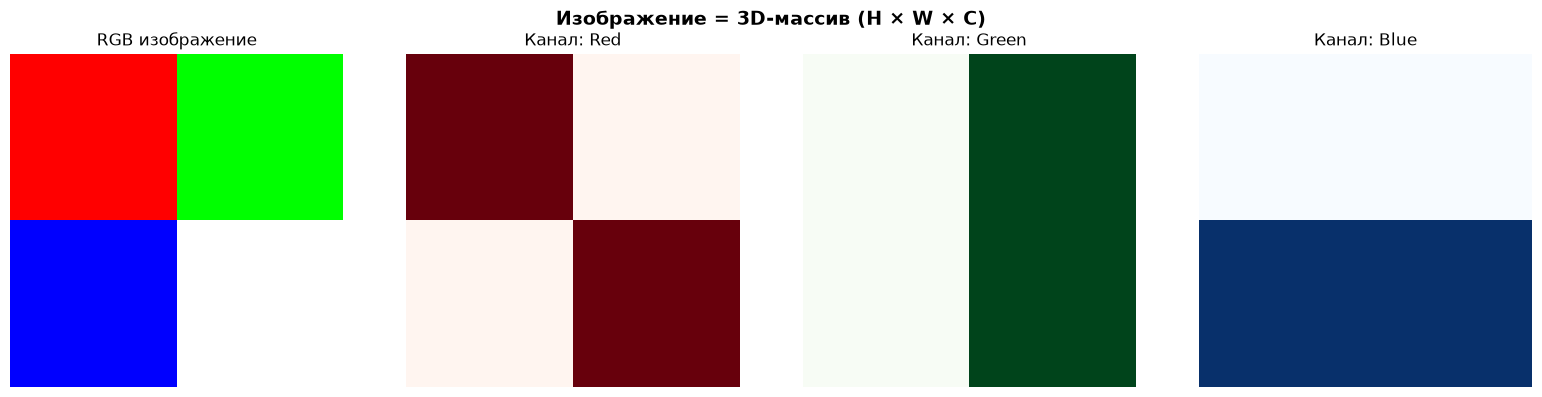

Форма массива: (8, 8, 3)  →  (высота, ширина, каналы)
Тип данных: uint8
Диапазон значений: [0, 255]


In [36]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import torch

# Создадим простое изображение вручную
# RGB-изображение 8x8 пикселей
img_array = np.zeros((8, 8, 3), dtype=np.uint8)

# Красный квадрат в левом верхнем углу
img_array[0:4, 0:4] = [255, 0, 0]

# Зелёный квадрат в правом верхнем углу
img_array[0:4, 4:8] = [0, 255, 0]

# Синий квадрат в левом нижнем углу
img_array[4:8, 0:4] = [0, 0, 255]

# Белый квадрат в правом нижнем углу
img_array[4:8, 4:8] = [255, 255, 255]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Полное изображение
axes[0].imshow(img_array)
axes[0].set_title('RGB изображение', fontsize=12)

# Отдельные каналы
channel_names = ['Red', 'Green', 'Blue']
cmaps = ['Reds', 'Greens', 'Blues']
for i in range(3):
    axes[i+1].imshow(img_array[:, :, i], cmap=cmaps[i], vmin=0, vmax=255)
    axes[i+1].set_title(f'Канал: {channel_names[i]}', fontsize=12)

for ax in axes:
    ax.axis('off')

plt.suptitle('Изображение = 3D-массив (H × W × C)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Форма массива: {img_array.shape}  →  (высота, ширина, каналы)")
print(f"Тип данных: {img_array.dtype}")
print(f"Диапазон значений: [{img_array.min()}, {img_array.max()}]")

### 2.2. Тензоры в PyTorch: формат изображений

**Важно:** В PyTorch изображения хранятся как тензоры формата `(C, H, W)` — каналы идут первыми!

NumPy shape:   (8, 8, 3)    →  (H, W, C)
Tensor shape:  torch.Size([3, 8, 8])  →  (C, H, W)
Tensor dtype:  torch.float32
Tensor range:  [0.0, 1.0]


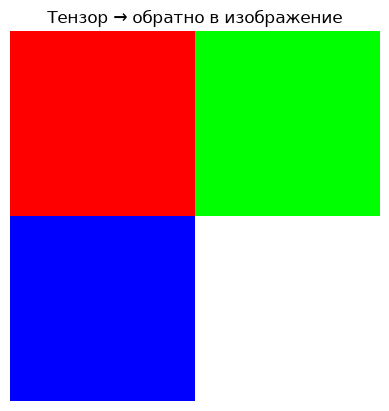

In [37]:
# NumPy: (H, W, C)  →  PyTorch: (C, H, W)
tensor_img = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0

print(f"NumPy shape:   {img_array.shape}    →  (H, W, C)")
print(f"Tensor shape:  {tensor_img.shape}  →  (C, H, W)")
print(f"Tensor dtype:  {tensor_img.dtype}")
print(f"Tensor range:  [{tensor_img.min():.1f}, {tensor_img.max():.1f}]")

# Обратное преобразование для визуализации
def tensor_to_image(tensor):
    """Конвертирует тензор (C, H, W) обратно в numpy (H, W, C) для matplotlib."""
    img = tensor.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)  # Ограничиваем диапазон [0, 1]
    return img

plt.imshow(tensor_to_image(tensor_img))
plt.title('Тензор → обратно в изображение')
plt.axis('off')
plt.show()

### Задание 1

Создайте массив NumPy 16×16 и нарисуйте на нём:
- Горизонтальный градиент (от чёрного к белому) в канале Red
- Вертикальный градиент в канале Green
- Канал Blue оставьте нулевым

Визуализируйте результат.

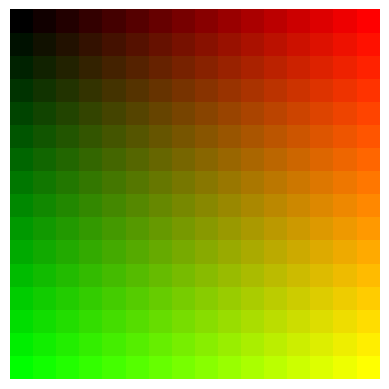

In [38]:
# === ВАШЕ РЕШЕНИЕ ===

gradient_img = np.zeros((16, 16, 3), dtype=np.uint8)

# Горизонтальный градиент в канале R
# заполните канал gradient_img[:, :, 0]
gradient_img[:,:,0] = np.linspace(0,255,16)

# Вертикальный градиент в канале G
# заполните канал gradient_img[:, :, 1]
gradient_img[:,:,1] = np.linspace(0,255,16).reshape(16, 1)

# Визуализация
# используйте plt.imshow()
plt.imshow(gradient_img)
plt.axis('off')
plt.show()

---
## Часть 3. Загрузка датасетов через torchvision

### 3.1. Загрузка CIFAR-10

In [39]:
import torchvision
import torchvision.transforms as transforms

# Базовое преобразование: PIL Image → Tensor
basic_transform = transforms.ToTensor()

# Загружаем CIFAR-10 (train)
train_dataset = torchvision.datasets.CIFAR10(
    root='../data',
    train=True,
    download=True,
    transform=basic_transform
)

# Загружаем CIFAR-10 (test)
test_dataset = torchvision.datasets.CIFAR10(
    root='../data',
    train=False,
    download=True,
    transform=basic_transform
)

# Названия классов
classes = train_dataset.classes

print(f"Обучающая выборка: {len(train_dataset)} изображений")
print(f"Тестовая выборка:  {len(test_dataset)} изображений")
print(f"Классы ({len(classes)}): {classes}")

# Посмотрим на одно изображение
image, label = train_dataset[0]
print(f"\nФорма тензора: {image.shape}  →  (C, H, W) = (3, 32, 32)")
print(f"Класс: {classes[label]} (индекс {label})")

Обучающая выборка: 50000 изображений
Тестовая выборка:  10000 изображений
Классы (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Форма тензора: torch.Size([3, 32, 32])  →  (C, H, W) = (3, 32, 32)
Класс: frog (индекс 6)


### 3.2. Визуализация изображений из датасета

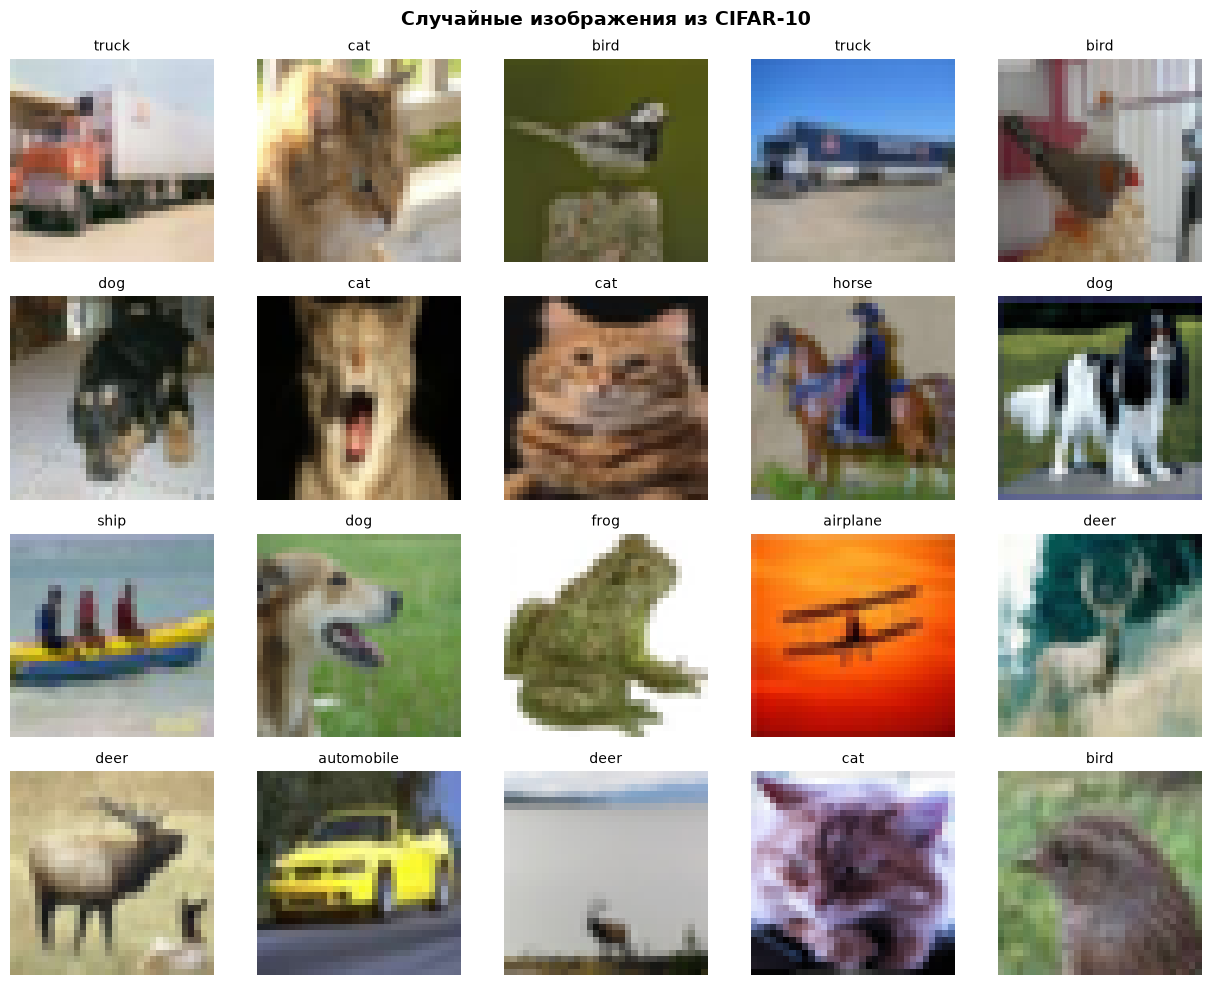

In [40]:
def show_images(dataset, num_images=20, cols=5):
    """Визуализирует случайные изображения из датасета."""
    rows = (num_images + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), num_images, replace=False)

    for i, idx in enumerate(indices):
        image, label = dataset[idx]
        # Тензор (C, H, W) → numpy (H, W, C)
        img_np = image.permute(1, 2, 0).numpy()
        axes[i].imshow(img_np)
        axes[i].set_title(dataset.classes[label], fontsize=10)
        axes[i].axis('off')

    # Скрыть пустые ячейки
    for i in range(num_images, len(axes)):
        axes[i].axis('off')

    plt.suptitle('Случайные изображения из CIFAR-10', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_images(train_dataset)

### 3.3. Распределение классов

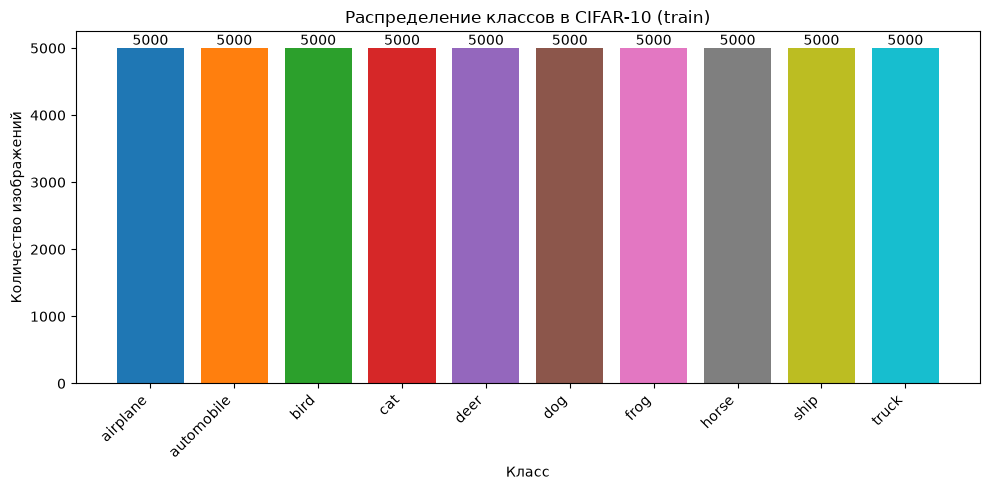

Вывод: CIFAR-10 — сбалансированный датасет (по 5000 на класс)


In [41]:
from collections import Counter

# Считаем количество изображений в каждом классе
label_counts = Counter(train_dataset.targets)

# Сортируем по индексу класса
sorted_counts = sorted(label_counts.items())
class_names = [classes[i] for i, _ in sorted_counts]
counts = [c for _, c in sorted_counts]

plt.figure(figsize=(10, 5))
bars = plt.bar(class_names, counts, color=plt.cm.tab10.colors[:len(classes)])
plt.xlabel('Класс')
plt.ylabel('Количество изображений')
plt.title('Распределение классов в CIFAR-10 (train)')
plt.xticks(rotation=45, ha='right')

# Добавляем числа на столбцы
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             str(count), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

print("Вывод: CIFAR-10 — сбалансированный датасет (по 5000 на класс)")

---
## Часть 4. Аугментации изображений

### 4.1. Зачем нужны аугментации?

**Аугментации** — это преобразования изображений, которые:
- Увеличивают эффективный размер датасета
- Повышают устойчивость (робастность) модели
- Борются с переобучением

**Ключевое правило:** аугментация не должна менять семантику (класс) изображения.

In [42]:
from torchvision import transforms
from PIL import Image

# Возьмём одно изображение из датасета (без трансформов)
raw_dataset = torchvision.datasets.CIFAR10(
    root='../data', train=True, download=False, transform=None
)
sample_image, sample_label = raw_dataset[42]  # PIL Image

print(f"Тип: {type(sample_image)}")
print(f"Размер: {sample_image.size}")
print(f"Класс: {classes[sample_label]}")

Тип: <class 'PIL.Image.Image'>
Размер: (32, 32)
Класс: bird


### 4.2. Демонстрация отдельных аугментаций

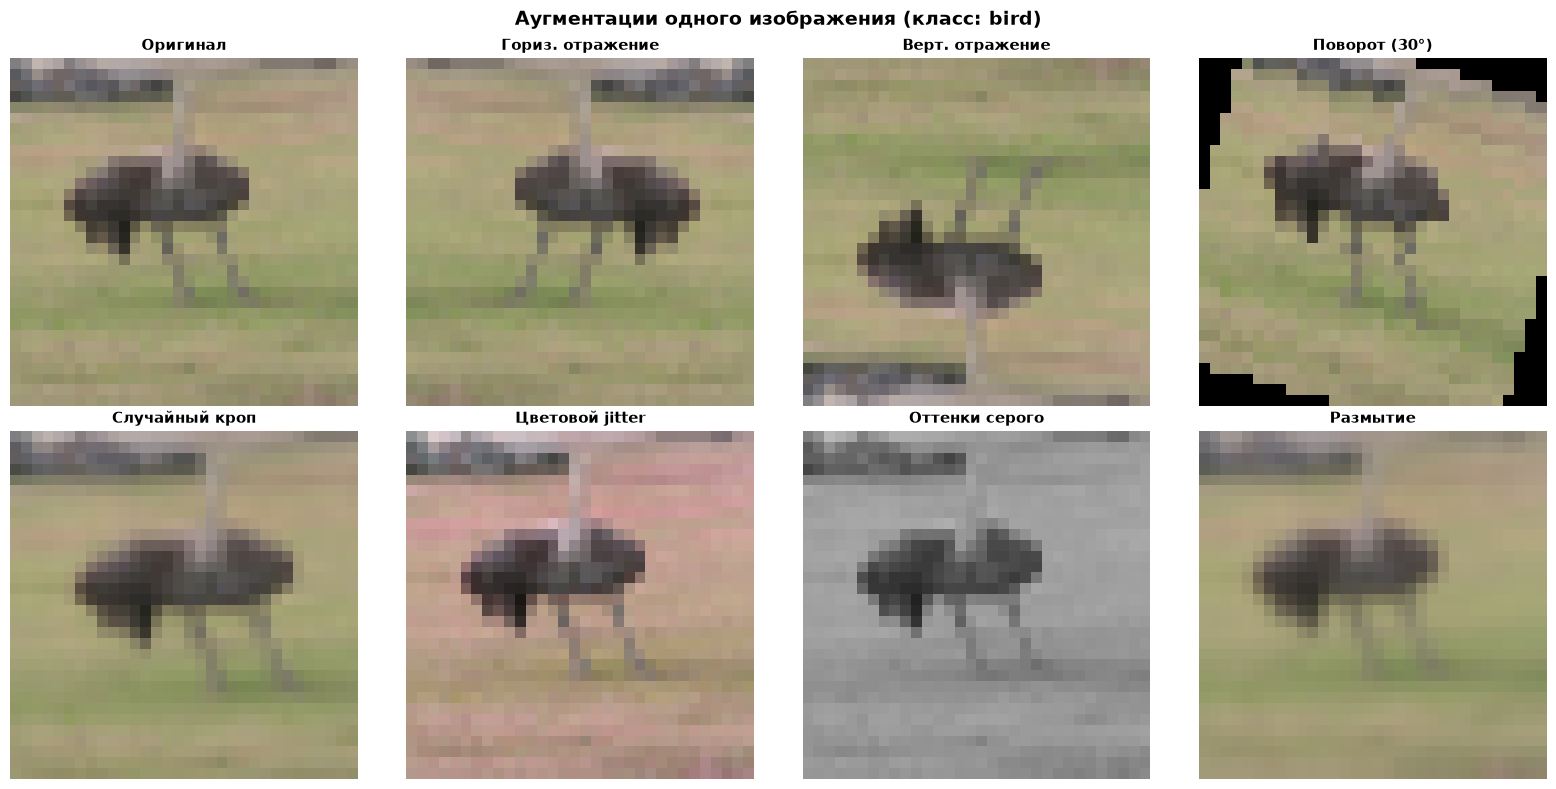

In [43]:
# Определяем различные аугментации
augmentations = {
    'Оригинал': transforms.Compose([]),
    'Гориз. отражение': transforms.RandomHorizontalFlip(p=1.0),
    'Верт. отражение': transforms.RandomVerticalFlip(p=1.0),
    'Поворот (30°)': transforms.RandomRotation(degrees=30),
    'Случайный кроп': transforms.RandomResizedCrop(32, scale=(0.5, 1.0)),
    'Цветовой jitter': transforms.ColorJitter(
        brightness=0.5, contrast=0.5, saturation=0.5, hue=0.3
    ),
    'Оттенки серого': transforms.RandomGrayscale(p=1.0),
    'Размытие': transforms.GaussianBlur(kernel_size=3, sigma=(0.5, 2.0)),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (name, aug) in enumerate(augmentations.items()):
    # Применяем аугментацию
    if name == 'Оригинал':
        aug_image = sample_image
    else:
        aug_image = aug(sample_image)

    axes[i].imshow(aug_image)
    axes[i].set_title(name, fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.suptitle(f'Аугментации одного изображения (класс: {classes[sample_label]})',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.3. Композиция аугментаций: типовой пайплайн

In [44]:
# Типовой пайплайн для обучения
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],  # Средние значения CIFAR-10
        std=[0.2470, 0.2435, 0.2616]     # Стандартные отклонения CIFAR-10
    ),
])

# Пайплайн для тестирования (без случайных аугментаций!)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    ),
])

print("Train transform:")
print(train_transform)
print("\nTest transform:")
print(test_transform)

print("\n⚠️ Важно: аугментации применяются ТОЛЬКО при обучении, не при тестировании!")

Train transform:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomCrop(size=(32, 32), padding=4)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
)

Test transform:
Compose(
    ToTensor()
    Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
)

⚠️ Важно: аугментации применяются ТОЛЬКО при обучении, не при тестировании!


### 4.4. Визуализация нескольких аугментированных версий одного изображения

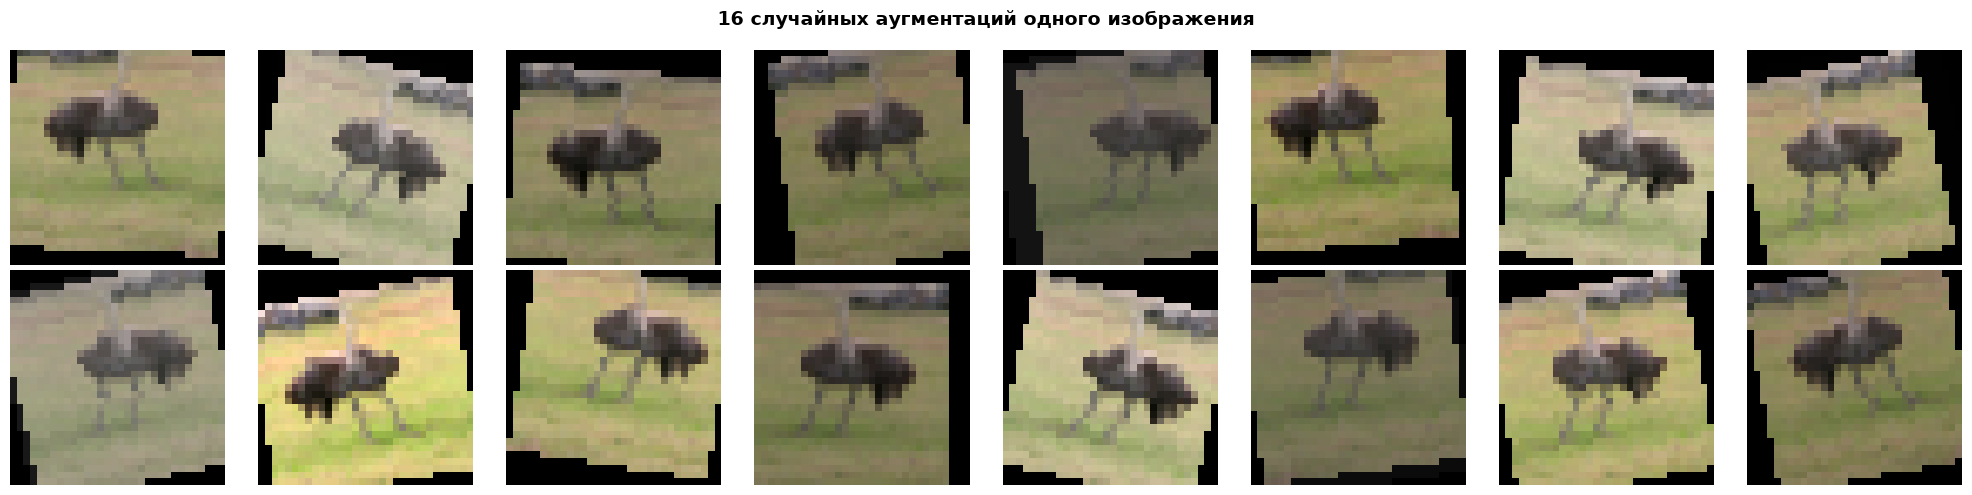

Каждый раз — случайная комбинация преобразований → бесконечное разнообразие!


In [45]:
# Пайплайн аугментации (без нормализации — для визуализации)
visual_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
axes = axes.flatten()

# Показываем 16 различных аугментаций одного изображения
for i in range(16):
    aug_tensor = visual_transform(sample_image)
    axes[i].imshow(aug_tensor.permute(1, 2, 0).numpy())
    axes[i].axis('off')

plt.suptitle('16 случайных аугментаций одного изображения',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Каждый раз — случайная комбинация преобразований → бесконечное разнообразие!")

### Задание 2

Создайте свой пайплайн аугментации, который включает:
1. Случайный поворот до 45 градусов
2. Случайное размытие (GaussianBlur)
3. Случайное изменение яркости и контраста
4. Преобразование в тензор

Визуализируйте 8 аугментированных версий любого изображения из CIFAR-10.

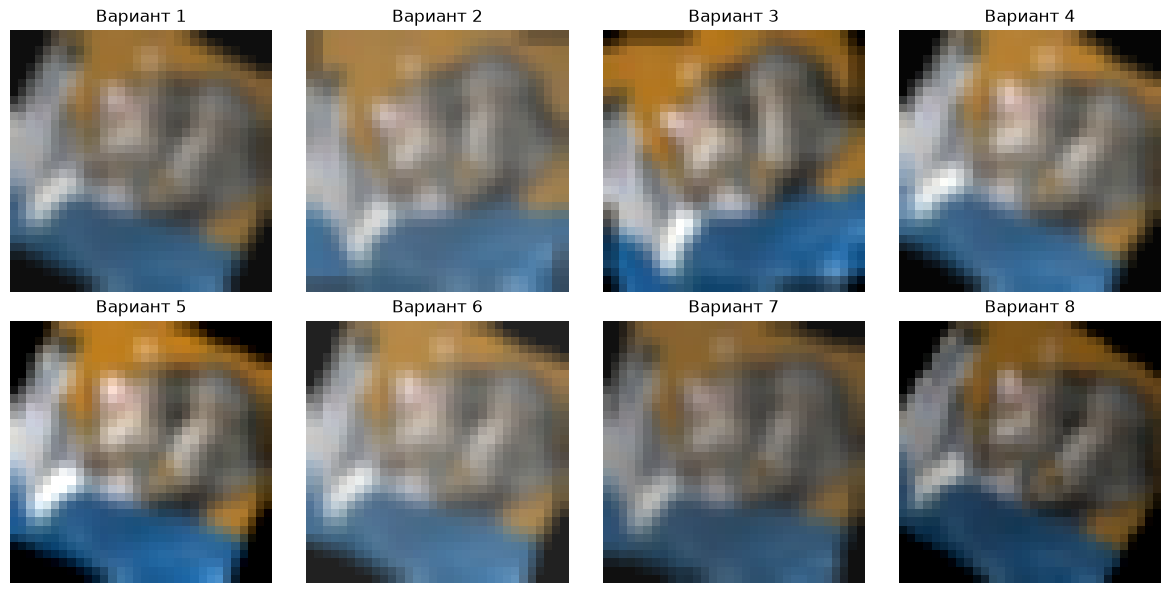

In [46]:
# === ВАШЕ РЕШЕНИЕ ===

import torchvision.transforms as transforms

train_dataset_my = torchvision.datasets.CIFAR10(
    root='../data',
    train=False,
    download=True,
)

my_transform = transforms.Compose([
transforms.RandomRotation(degrees=45),
transforms.GaussianBlur(kernel_size=3, sigma=(0.5, 2.0)),
transforms.ColorJitter(brightness=0.3, contrast=0.3),
transforms.ToTensor()
])

img, label = train_dataset_my[0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten() # axes - 2 на 4 массив, а flatten преобразует в строкуы

# визуализируйте результаты

for i in range(8):
    augmented_img = my_transform(img)
    axes[i].imshow(augmented_img.permute(1, 2, 0).numpy())
    axes[i].axis('off')
    axes[i].set_title(f'Вариант {i+1}')

plt.tight_layout()
plt.show()

---
## Часть 5. Нормализация и статистика датасета

### 5.1. Вычисление среднего и стандартного отклонения

In [47]:
# Загружаем датасет только с ToTensor (без нормализации)
temp_dataset = torchvision.datasets.CIFAR10(
    root='../data', train=True, download=False,
    transform=transforms.ToTensor()
)

# Вычисляем среднее и std по всему датасету
# Способ 1: через DataLoader
loader = torch.utils.data.DataLoader(temp_dataset, batch_size=1024, shuffle=False)

mean = torch.zeros(3)
std = torch.zeros(3)
n_samples = 0

for images, _ in loader:
    batch_size = images.size(0)
    images = images.view(batch_size, 3, -1)  # (B, C, H*W)
    mean += images.mean(dim=[0, 2]) * batch_size
    std += images.std(dim=[0, 2]) * batch_size
    n_samples += batch_size

mean /= n_samples
std /= n_samples

print(f"Среднее по каналам (R, G, B): {mean.tolist()}")
print(f"Стд. отклонение (R, G, B):    {std.tolist()}")
print(f"\nЭти значения используются в transforms.Normalize()")
print(f"Формула: normalized = (pixel - mean) / std")

Среднее по каналам (R, G, B): [0.4913996160030365, 0.482158362865448, 0.44653090834617615]
Стд. отклонение (R, G, B):    [0.24698610603809357, 0.24343806505203247, 0.2615237236022949]

Эти значения используются в transforms.Normalize()
Формула: normalized = (pixel - mean) / std


### 5.2. Эффект нормализации

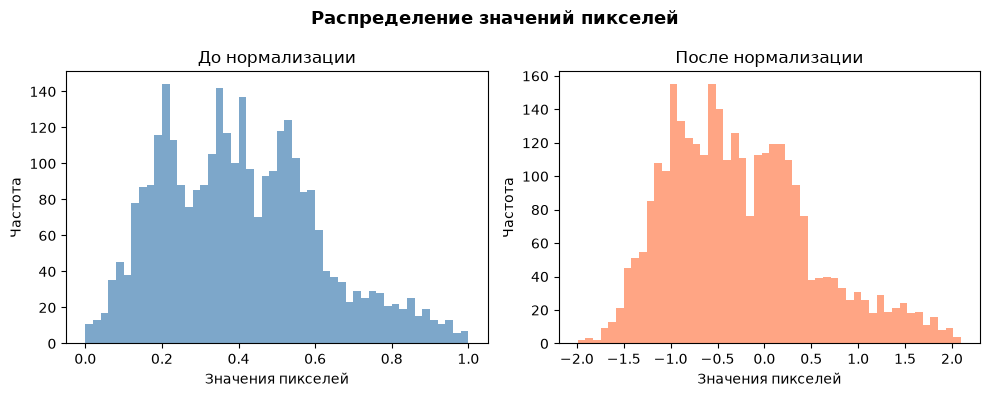

До:    min=0.000, max=1.000, mean=0.406
После: min=-1.990, max=2.095, mean=-0.261


In [48]:
# Берём один батч
images_raw, _ = next(iter(loader))

# Нормализуем
normalize = transforms.Normalize(mean=mean, std=std)
images_norm = normalize(images_raw[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# До нормализации
axes[0].hist(images_raw[0].numpy().flatten(), bins=50, alpha=0.7, color='steelblue')
axes[0].set_title('До нормализации')
axes[0].set_xlabel('Значения пикселей')
axes[0].set_ylabel('Частота')

# После нормализации
axes[1].hist(images_norm.numpy().flatten(), bins=50, alpha=0.7, color='coral')
axes[1].set_title('После нормализации')
axes[1].set_xlabel('Значения пикселей')
axes[1].set_ylabel('Частота')

plt.suptitle('Распределение значений пикселей', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"До:    min={images_raw[0].min():.3f}, max={images_raw[0].max():.3f}, mean={images_raw[0].mean():.3f}")
print(f"После: min={images_norm.min():.3f}, max={images_norm.max():.3f}, mean={images_norm.mean():.3f}")

---
## Итоги практики

